In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt

In [24]:
class Value:
    def __init__(self,data,_children=(),_op='',label=''):
        self.data=data
        self.grad=0.0 # Default gradient
        self._prev=set(_children)
        self._op=_op
        self.label=label
    def __repr__(self):
        return f"Value(data={self.data})"
    def __add__(self,other):
        result=Value(self.data+other.data,(self,other),'+')
        return result
    def __mul__(self,other):
        result=Value(self.data*other.data,(self,other),'*')
        return result

a=Value(2.0,label='a')
b=Value(-3.0,label='b')
c=Value(10.0,label='c')
e=a*b ; e.label ='e'
d=e+c;d.label='d'
f=Value(-2.0,label='f')
L=d*f; L.label='L'
L

Value(data=-8.0)

In [25]:
from graphviz import Digraph

def trace(root):
  # builds a set of all nodes and edges in a graph
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)
  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
  
  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)

  return dot

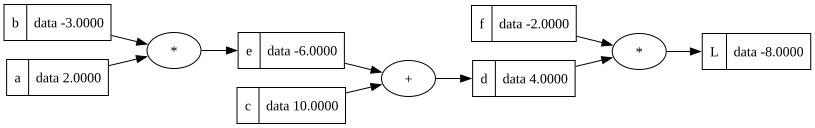

In [21]:
draw_dot(L)

## Manual Backpropagation

In [46]:
def test():
    h=0.001
    a=Value(2.0,label='a')
    b=Value(-3.0,label='b')
    c=Value(10.0,label='c')
    e=a*b ; e.label ='e'
    d=e+c;d.label='d'
    f=Value(-2.0,label='f')
    L=d*f; L.label='L'
    L1=L.data

    a=Value(2.0+h,label='a')
    b=Value(-3.0,label='b')
    c=Value(10.0,label='c')
    e=a*b ; e.label ='e'
    d=e+c;d.label='d'
    f=Value(-2.0,label='f')
    L=d*f; L.label='L'
    L2=L.data

    print((L2-L1)/h)

test()

6.000000000000227


In [30]:
L.grad=1

L=d*f  

Derivative  
dL/dd=f  
dL/df=d

In [34]:
d.grad=-2
f.grad=4

dL/dc=dd/dc * dL/dd

d=c+e  
dd/dc=1

dL/de=dd/de * dL/dd  
dd/de=1

In [40]:
e.grad=-2
c.grad=-2

dL/db=de/db * dL/de  

e=b*a  
de/db=a  
de/da=b

In [43]:
b.grad=-4
a.grad=6

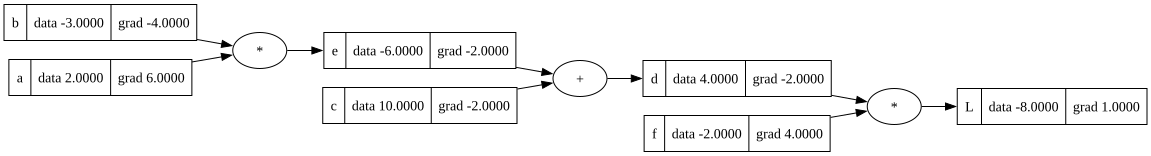

In [44]:
draw_dot(L)